**STUDENT PERFORMANCE PREDICTION**

IMPORTING LIBRARIES

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.feature_selection import mutual_info_regression
from sklearn.preprocessing import StandardScaler


LOADING DATASET

In [ ]:
df = pd.read_csv('/content/Student_performance_data.csv')

print("Data Loaded successfully ")
print("Shape:", df.shape)
df.head()

Data Loaded successfully 
Shape: (2392, 15)


,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
0,1001,17,1,0,2,19.833723,7,1,2,0,0,1,0,2.929196,2.0
1,1002,18,0,0,1,15.408756,0,0,1,0,0,0,0,3.042915,1.0
2,1003,15,0,2,3,4.210570,26,0,2,0,0,0,0,0.112602,4.0
3,1004,17,1,0,3,10.028829,14,0,3,1,0,0,0,2.054218,3.0
4,1005,17,1,0,2,4.672495,17,1,3,0,0,0,0,1.288061,4.0


DESCRIBING DATASET

In [ ]:
df.info()
display(df.describe())

print("Missing Values:\n", df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2392 entries, 0 to 2391
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   StudentID          2392 non-null   int64  
 1   Age                2392 non-null   int64  
 2   Gender             2392 non-null   int64  
 3   Ethnicity          2392 non-null   int64  
 4   ParentalEducation  2392 non-null   int64  
 5   StudyTimeWeekly    2392 non-null   float64
 6   Absences           2392 non-null   int64  
 7   Tutoring           2392 non-null   int64  
 8   ParentalSupport    2392 non-null   int64  
 9   Extracurricular    2392 non-null   int64  
 10  Sports             2392 non-null   int64  
 11  Music              2392 non-null   int64  
 12  Volunteering       2392 non-null   int64  
 13  GPA                2392 non-null   float64
 14  GradeClass         2392 non-null   float64
dtypes: float64(3), int64(12)
memory usage: 280.4 KB


,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
count,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000
mean,2196.500000,16.468645,0.510870,0.877508,1.746237,9.771992,14.541388,0.301421,2.122074,0.383361,0.303512,0.196906,0.157191,1.906186,2.983696
std,690.655244,1.123798,0.499986,1.028476,1.000411,5.652774,8.467417,0.458971,1.122813,0.486307,0.459870,0.397744,0.364057,0.915156,1.233908
min,1001.000000,15.000000,0.000000,0.000000,0.000000,0.001057,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1598.750000,15.000000,0.000000,0.000000,1.000000,5.043079,7.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.174803,2.000000
50%,2196.500000,16.000000,1.000000,0.000000,2.000000,9.705363,15.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,1.893393,4.000000
75%,2794.250000,17.000000,1.000000,2.000000,2.000000,14.408410,22.000000,1.000000,3.000000,1.000000,1.000000,0.000000,0.000000,2.622216,4.000000
max,3392.000000,18.000000,1.000000,3.000000,4.000000,19.978094,29.000000,1.000000,4.000000,1.000000,1.000000,1.000000,1.000000,4.000000,4.000000


Missing Values:
 StudentID            0
Age                  0
Gender               0
Ethnicity            0
ParentalEducation    0
StudyTimeWeekly      0
Absences             0
Tutoring             0
ParentalSupport      0
Extracurricular      0
Sports               0
Music                0
Volunteering         0
GPA                  0
GradeClass           0
dtype: int64


HEATMAP FOR UNDERSTANDING CORRELATION BETWEEN FEATURES

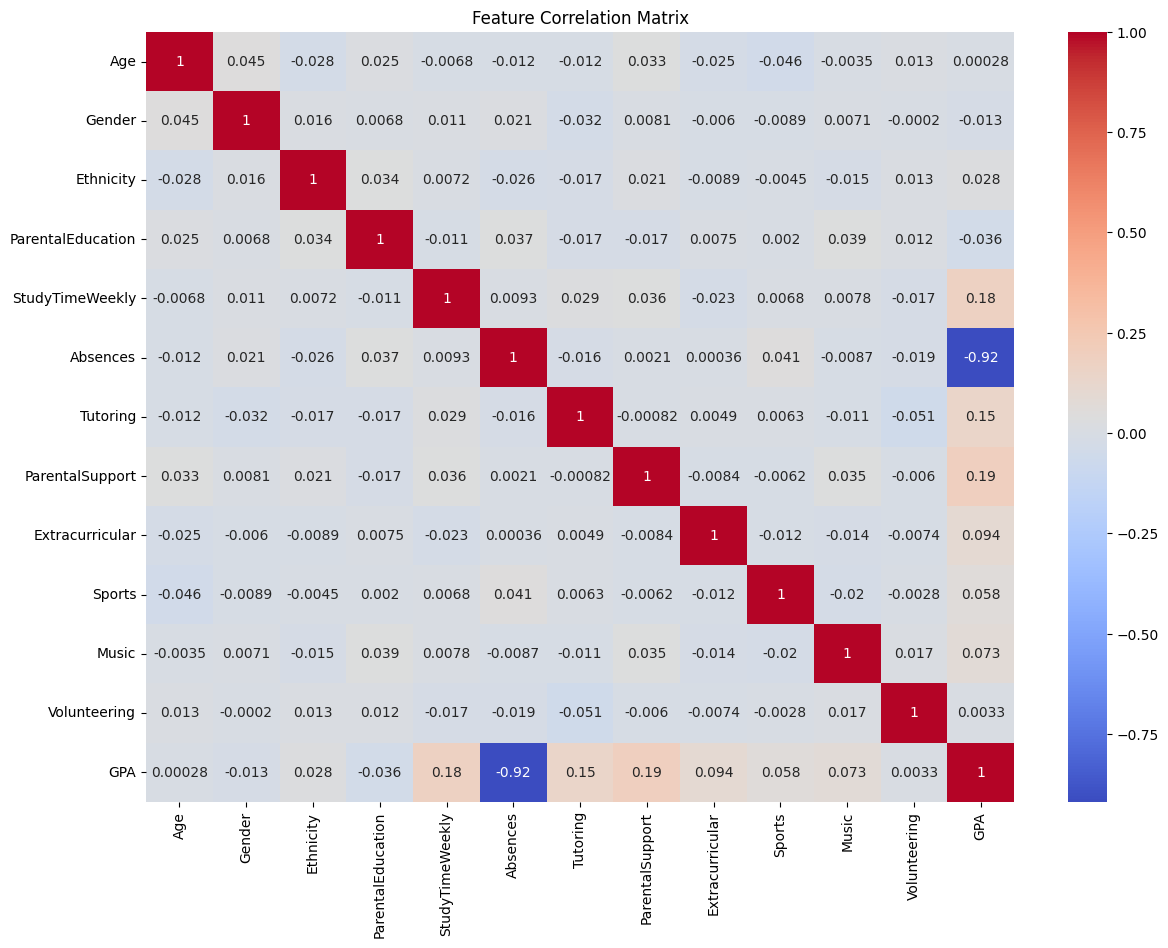

In [ ]:
plt.figure(figsize=(14, 10))
corr = df.drop(['StudentID', 'GradeClass'], axis=1).corr()
sns.heatmap(corr,annot=True, cmap='coolwarm')

plt.title('Feature Correlation Matrix')
plt.show()

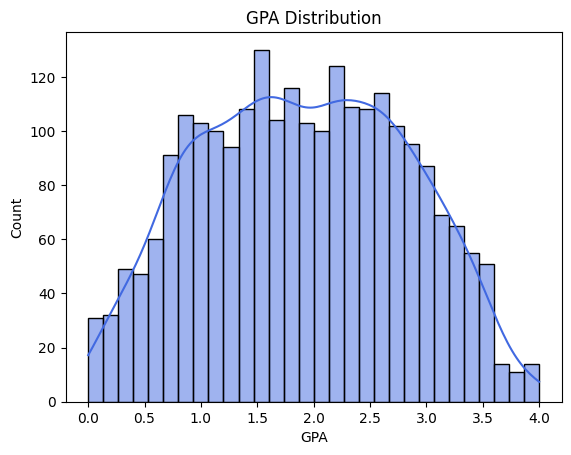

In [ ]:
plt.figure()
sns.histplot(df['GPA'], kde=True, bins=30, color='royalblue')
plt.title("GPA Distribution")
plt.show()

In [ ]:
# GPA is target → we are explaining factors affecting it
X = df.drop(['StudentID', 'GPA', 'GradeClass'], axis=1)
y = df['GPA']

print("Features:", list(X.columns))

Features: ['Age', 'Gender', 'Ethnicity', 'ParentalEducation', 'StudyTimeWeekly', 'Absences', 'Tutoring', 'ParentalSupport', 'Extracurricular', 'Sports', 'Music', 'Volunteering']


,Feature,Score
5,Absences,0.889317
6,Tutoring,0.027130
7,ParentalSupport,0.024459
0,Age,0.017291
8,Extracurricular,0.016271
11,Volunteering,0.004923
10,Music,0.004063
4,StudyTimeWeekly,0.003728
3,ParentalEducation,0.003433
9,Sports,0.003087


/tmp/ipykernel_7183/568372416.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Score', y='Feature', data=mi_df, palette='viridis')


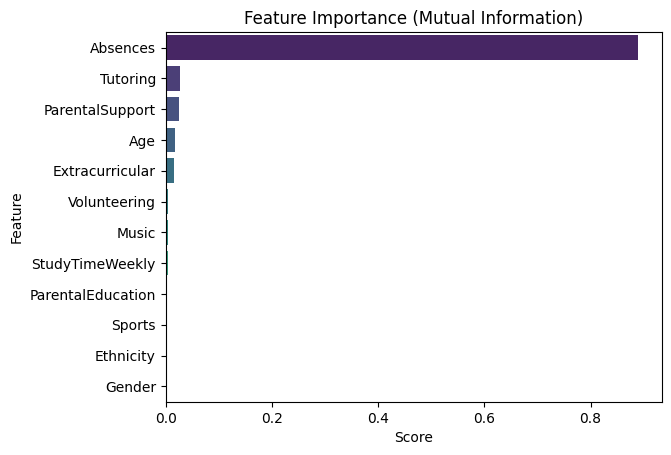


Key Insights:

Top factors influencing GPA:
           Feature     Score
5         Absences  0.889317
6         Tutoring  0.027130
7  ParentalSupport  0.024459

Least impactful factors:
     Feature     Score
9     Sports  0.003087
2  Ethnicity  0.000000
1     Gender  0.000000


In [ ]:
mi_scores = mutual_info_regression(X, y, random_state=42)

mi_df = pd.DataFrame({
    'Feature': X.columns,
    'Score': mi_scores
}).sort_values(by='Score', ascending=False)

display(mi_df)

sns.barplot(x='Score', y='Feature', data=mi_df, palette='viridis')
plt.title("Feature Importance (Mutual Information)")
plt.show()

print("\nKey Insights:")
print("\nTop factors influencing GPA:")
print(mi_df.head(3))

print("\nLeast impactful factors:")
print(mi_df.tail(3))

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42)
}

results = []
trained_models = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    preds = model.predict(X_test)

    mae = mean_absolute_error(y_test, preds)
    r2 = r2_score(y_test, preds)

    results.append({"Model": name, "MAE": mae, "R2": r2})
    trained_models[name] = model

,Model,MAE,R2
1,Ridge Regression,0.155273,0.953253
0,Linear Regression,0.155295,0.953247
2,Random Forest,0.190824,0.926844


/tmp/ipykernel_7183/1268662188.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='R2', y='Model', data=results_df, palette='Blues_r')


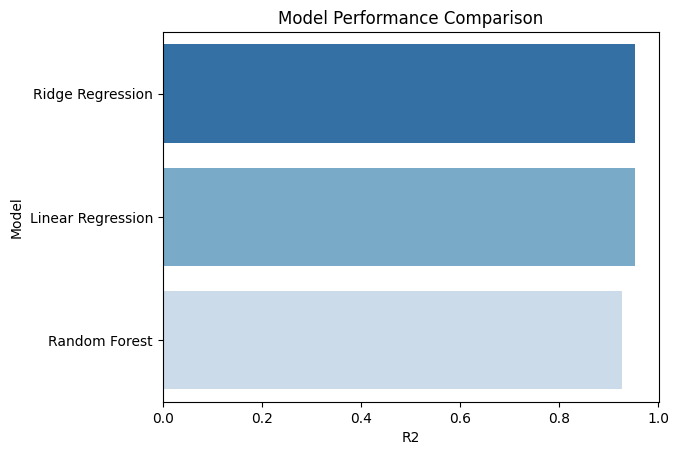

In [ ]:
results_df = pd.DataFrame(results).sort_values(by='R2', ascending=False)
display(results_df)

sns.barplot(x='R2', y='Model', data=results_df, palette='Blues_r')
plt.title("Model Performance Comparison")
plt.show()

In [ ]:
best_model_name = results_df.iloc[0]['Model']
best_model = trained_models[best_model_name]

print("Best Model:", best_model_name)

Best Model: Ridge Regression


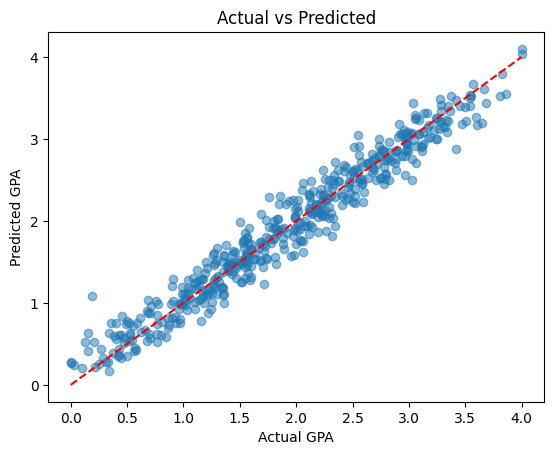

In [ ]:
preds = best_model.predict(X_test)

plt.scatter(y_test, preds, alpha=0.5)
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--')
plt.xlabel("Actual GPA")
plt.ylabel("Predicted GPA")
plt.title("Actual vs Predicted")
plt.show()

In [ ]:
manual_input = {
    'Age': [16],
    'Gender': [0],
    'Ethnicity': [1],
    'ParentalEducation': [3],
    'StudyTimeWeekly': [19.2],
    'Absences': [1],
    'Tutoring': [1],
    'ParentalSupport': [4],
    'Extracurricular': [1],
    'Sports': [0],
    'Music': [1],
    'Volunteering': [1]
}

input_df = pd.DataFrame(manual_input)
input_df = input_df.reindex(columns=X.columns, fill_value=0)

scaler = StandardScaler()
scaler.fit(X_train)

input_scaled = scaler.transform(input_df)

prediction = best_model.predict(input_scaled)[0]

print("Predicted GPA:",round(prediction,2))
# Providing interpretation of the score
if prediction >= 3.5:
    rating = "Outstanding"
elif  prediction>= 2.5:
    rating = "Good,keep it up"
else:
    rating = "Improvement needed"

print(f"Performance Forecast: {rating}")

Predicted GPA: 3.86
Performance Forecast: Outstanding


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but Ridge was fitted with feature names
  warnings.warn(
